#Multi-Agent summary System

> **Code assistants used:** Opencode + Deepseek

Multi-agent system with **Orchestrator → MathAgent | KnowledgeAgent -> Summary -> orchestrator**.

**Architecture:** all ReAct loops are implemented manually — no `create_react_agent`.
Tool calls are read from the JSON payload of each `AIMessage.tool_calls`, executed
explicitly, and fed back as `HumanMessage` objects (because the model had problems with `ToolMessage`).

## 1 · Environment & Imports

In [ ]:
import json
import os
import re
import sys
import time
import random
import warnings
from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore", category=DeprecationWarning)

# ── Rilevamento ambiente ──────────────────────────────────────────────────
IN_COLAB  = False
IN_KAGGLE = False

if "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/working"):
    IN_KAGGLE = True
else:
    try:
        import google.colab
        if os.path.exists("/var/colab/hostname"):
            IN_COLAB = True
    except ImportError:
        pass

# ── Percorsi ─────────────────────────────────────────────────────────────
if IN_COLAB:
    from google.colab import drive
    print("Monto Google Drive...")
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/NLP")
elif IN_KAGGLE:
    BASE_DIR = Path("/kaggle/working/NLP_project")
    BASE_DIR.mkdir(parents=True, exist_ok=True)
else:
    BASE_DIR = Path("./")

if BASE_DIR.exists():
    os.chdir(BASE_DIR)
    print(f"Cartella di lavoro: {os.getcwd()}")
else:
    print(f"Percorso non trovato: {BASE_DIR}")

if str(BASE_DIR.resolve()) not in sys.path:
    sys.path.append(str(BASE_DIR.resolve()))

RUNS_DIR = Path("./data/runs")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Environment:", "KAGGLE" if IN_KAGGLE else "COLAB" if IN_COLAB else "LOCAL")
print("Runs directory:", RUNS_DIR)

Monto Google Drive...
Mounted at /content/drive
Cartella di lavoro: /content/drive/.shortcut-targets-by-id/1DkQfKRLA_djmSfGNlEcF1sUVIz_irFja/NLP
Environment: COLAB
Runs directory: data/runs


## 2 · Install dependencies

In [ ]:
if IN_COLAB:
    !pip install -q colab-xterm
    !pip install -q \
        langchain langchain-community langchain-ollama langgraph \
        wikipedia ddgs python-dotenv rank_bm25

    %load_ext colabxterm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.6/115.6 kB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.7/161.7 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


## 3 · Terminal (start Ollama)

Run inside the terminal opened by `%xterm`:
```bash
sudo apt-get install -y zstd
curl -fsSL https://ollama.com/install.sh | sh
ollama serve & ollama pull phi4-mini
```

In [ ]:
if IN_COLAB:
    %xterm

Launching Xterm...

<IPython.core.display.Javascript object>

## 4 · Configuration

Edit `MODEL_CONFIG` to assign different Ollama models to individual agents.
`GAME_USER` and `GAME_PASS` are read from environment variables (`.env` file or export).

In [ ]:
import dotenv
dotenv.load_dotenv()

# ── Model per agent ──────────────────────────────────────────────────────
# Change one agent's model without touching the others.
MODEL_CONFIG = {
    "orchestrator": "phi4-mini",
    "math":         "phi4-mini",
    "knowledge":    "phi4-mini",
    "single":       "phi4-mini",
}
MAX_STEPS = {
    "orchestrator": 1,
    "math":         3,
    "knowledge":    3,
}

# ── Run parameters ───────────────────────────────────────────────────────
REASONING   = False                               # True for thinking mode
RERANK      = False                                # BM25 paragraph re-ranking on wikipedia search
NUM_RUNS    = 1                                   # games per competition
MAX_LEVELS  = 15                                  # fixed maximum levels
RUN_COMMENT = "multi-agent: orchestrator + math + knowledge — manual tool calling"
TECHNIQUES  = ["multi-agent", "RAG-wikipedia", "RAG-duckduckgo", "tool-calling"]

# ── API credentials ──────────────────────────────────────────────────────
# GAME_USER / GAME_PASS avoid collision with the $USER system variable (Linux/Colab).
API_URL   = "http://131.175.15.22:51111/"
GAME_USER = os.getenv("USER")
GAME_PASS = os.getenv("PASSWORD")

print("MODEL_CONFIG:", MODEL_CONFIG)
print(f"NUM_RUNS: {NUM_RUNS}  |  MAX_LEVELS: {MAX_LEVELS}")
print("GAME_USER:", GAME_USER)

MODEL_CONFIG: {'orchestrator': 'phi4-mini', 'math': 'phi4-mini', 'knowledge': 'phi4-mini', 'single': 'phi4-mini'}
NUM_RUNS: 1  |  MAX_LEVELS: 15
GAME_USER: lillaro


## 5 · Logging functions

Identical to `analysis.ipynb` (full compatibility with analysis cells).

**Changes vs original:**
- `save_metadata` accepts `model_config` (dict) instead of `model_name` (str)
- `update_runs_log` includes the `model_config` field in the log entry

In [ ]:
def _sanitize(text, max_len=24):
    # Make string filesystem-safe
    return "".join(c if c.isalnum() or c in "_-" else "_" for c in text)[:max_len].strip("_")


def create_run_folder(model_name):
    ts = datetime.now().strftime("%Y%m%d%H%M")
    name =  ts+  "_" + _sanitize(model_name)
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    print("Run folder created:", run_dir.name)
    return run_dir


def save_metadata(run_dir, model_config, reasoning, comment, techniques, num_runs):
    """Write .run_info.json immediately — survives a mid-run crash."""
    meta = {
        "model_name":               model_config.get("orchestrator", "unknown"),
        "model_config":             model_config,
        "reasoning":                reasoning,
        "comment":                  comment,
        "techniques":               techniques,
        "timestamp":                datetime.now().isoformat(),
        "num_runs_per_competition": num_runs,
    }
    with open(run_dir / ".run_info.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    return meta


def compute_competition_summary(attempts_log):
    # Accuracy = correct / (num_attempts * max_levels)
    # Penalizes early exits: finishing at level 5 of 15 contributes 4/15, not 4/4
    total_q = total_l = correct_q = timeout_q = 0
    total_time = 0.0
    all_earned = []
    max_level_reached = 0
    for attempt in attempts_log:
        max_level_reached = attempt['final_level'] if attempt['final_level']> max_level_reached else max_level_reached
        total_l += attempt['final_level']
        all_earned.append(attempt['earned'])
        for q in attempt['questions']:
            total_q += 1
            total_time += q['time']
            if q['timed_out']:
                timeout_q += 1
            elif q['correct'] is True:
                correct_q += 1
    denominator = len(attempts_log) * MAX_LEVELS
    return {
        'total_attempts': len(attempts_log),
        'questions_answered': total_q,
        'avg_level': round(total_l / len(attempts_log), 2) if attempts_log else 0,
        'max_level': max_level_reached,
        'avg_earned': round(sum(all_earned) / len(all_earned), 2) if all_earned else 0,
        'max_earned': max(all_earned) if all_earned else 0,
        'accuracy': round(correct_q / denominator, 4) if denominator > 0 else 0,
        'timeout_count': timeout_q,
        'avg_time_per_question': round(total_time / total_q, 4) if total_q > 0 else 0,
        'max_time': round(max(q['time'] for attempt in attempts_log for q in attempt['questions']), 4) if total_q > 0 else 0,
    }


def save_competition_result(run_dir, comp, attempts_log):
    filename = "comp_" + str(comp.id) + "_" + _sanitize(comp.name) + ".json"
    data = {
        "competition_id":   comp.id,
        "competition_name": comp.name,
        "summary":          compute_competition_summary(attempts_log),
        "attempts":         attempts_log,
    }
    with open(run_dir / filename, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print("  Saved:", filename)


def save_run_summary(run_dir, all_comp_data, metadata):
    correct_total = denominator_total = 0
    per_comp = {}
    for comp_id, comp_info in all_comp_data.items():
        s = compute_competition_summary(comp_info["attempts"])
        per_comp[str(comp_id)] = {
            "name":      comp_info["name"],
            "accuracy":  s["accuracy"],
            "avg_level": s["avg_level"],
            "avg_earned": s["avg_earned"],
        }
        denominator_total += s["total_attempts"] * comp_info["max_levels"]
        for attempt in comp_info["attempts"]:
            for q in attempt["questions"]:
                if q["correct"] is True:
                    correct_total += 1
    run_info = {
        **metadata,
        "total_competitions": len(all_comp_data),
        "overall_accuracy":   round(correct_total / denominator_total, 4) if denominator_total > 0 else 0,
        "comp_info":          per_comp,
    }
    with open(run_dir / ".run_info.json", "w", encoding="utf-8") as f:
        json.dump(run_info, f, indent=2)
    print("  Saved: .run_info.json")
    return run_info


def update_runs_log(runs_dir, run_folder, run_info):
    log_path = runs_dir / "runs_log.json"
    entries = []
    if log_path.exists():
        with open(log_path, "r", encoding="utf-8") as f:
            entries = json.load(f)
    competition_summary = {
        info["name"]: info["accuracy"]
        for info in run_info["comp_info"].values()
    }
    entries.append({
        "run_folder":           run_folder,
        "model_name":           run_info["model_name"],
        "model_config":         run_info.get("model_config", {}),
        "total_runs":           run_info["num_runs_per_competition"],
        "overall_accuracy":     run_info["overall_accuracy"],
        "reasoning":            run_info["reasoning"],
        "comment":              run_info["comment"],
        "techniques":           run_info["techniques"],
        "competition_accuracy": competition_summary,
    })
    with open(log_path, "w", encoding="utf-8") as f:
        json.dump(entries, f, indent=2)
    print("runs_log.json updated —", len(entries), "runs logged")

print("Logging functions loaded")

Logging functions loaded


## 6 · API Client

In [ ]:
from millionaire_client import MillionaireClient, AuthenticationError

client = MillionaireClient(API_URL)
try:
    user = client.login(GAME_USER, GAME_PASS)
    print("Login successful. Welcome,", user.username)
except AuthenticationError as e:
    print("Login failed:", e)

Login successful. Welcome, lillaro


## 7 · Common utilities

`make_model` is the single entry point for instantiating models.
`extract_agent_trace` and `print_agent_stats` handle debugging and tracing.

In [ ]:
from langchain_ollama import ChatOllama
from langchain.tools import tool
from langchain_core.tools import render_text_description
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
import textwrap


def make_model(model_name: str, temperature: float = 0.0) -> ChatOllama:
    """Instantiate a ChatOllama. Single entry point for model parameters."""
    return ChatOllama(model=model_name, temperature=temperature, num_predict=200)


def extract_agent_trace(result: dict) -> dict:
    """
    Extract the execution trace from a manual ReAct loop result.

    Returns
    -------
    dict with fields:
        model        — model name used
        raw_output   — raw text of the last AIMessage
        tools_called — list of {name, args} for each tool invoked
    """
    messages = result.get("messages", [])
    raw = messages[-1].content if messages else ""
    meta = getattr(messages[-1], "response_metadata", {}) if messages else {}
    tools_called = []
    for msg in messages:
        if hasattr(msg, "tool_calls") and msg.tool_calls:
            tools_called.extend(msg.tool_calls)
    return {"model": meta.get('model', 'Unknown'), "raw_output": raw, "tools_called": tools_called}


def print_agent_stats(result: dict, agent_name: str = "Agent"):
    """
    Print agent statistics in a box format.
    The prompt is printed in full with automatic line wrapping.
    """
    W = 150  # inner box width

    def row(text=""):
        return f"║  {text:<{W - 2}}║"

    def div():
        return "╠" + "═" * W + "╣"

    def wrap_rows(label, text, indent=0):
        """Print `label` on the first line, then wrap text into subsequent lines."""
        prefix = " " * indent
        inner_w = W - 2 - indent
        lines_out = []
        if label:
            lines_out.append(row(label))
        for src_line in text.splitlines():
            if src_line.strip() == "":
                lines_out.append(row(prefix))
                continue
            for chunk in textwrap.wrap(src_line, width=inner_w) or [src_line]:
                lines_out.append(row(prefix + chunk))
        return "\n".join(lines_out)

    messages  = result.get("messages", [])
    ai_msg    = messages[-1] if messages else None
    human_msg = next((m for m in messages if isinstance(m, HumanMessage)), None)
    meta      = getattr(ai_msg, "response_metadata", {}) if ai_msg else {}
    display_model = meta.get("model", "unknown")

    print()
    print("╔" + "═" * W + "╗")
    header = f"AGENT: {agent_name}"
    print(row(header[: W - 2]))
    print(div())

    prompt_text = human_msg.content if human_msg else ""
    print(row("PROMPT"))
    print(wrap_rows("", prompt_text, indent=2))
    print(div())

    usage = getattr(ai_msg, "usage_metadata", {}) if ai_msg else {}
    if usage:
        tok = f"TOKENS   in: {usage.get('input_tokens', 0)}   out: {usage.get('output_tokens', 0)}   tot: {usage.get('total_tokens', 0)}"
        print(row(tok))

    if meta and "total_duration" in meta:
        tot_s    = meta["total_duration"]               / 1e9
        prompt_s = meta.get("prompt_eval_duration", 0) / 1e9
        eval_s   = meta.get("eval_duration", 0)        / 1e9
        print(row(f"TIME     prompt: {prompt_s:.2f}s   gen: {eval_s:.2f}s   tot: {tot_s:.2f}s"))

    print("╚" + "═" * W + "╝")

print("Utils loaded")

# ── Timing utilities (for single-agent fused agent) ───────────────────────
_timing: dict = {}

def _reset_timing():
    global _timing
    _timing = {"agents": {}, "tools": {}}

def _record_agent_model(agent_name: str, elapsed: float):
    _timing["agents"].setdefault(agent_name, {"model": 0.0, "tools": {}})
    _timing["agents"][agent_name]["model"] += elapsed

def _record_agent_tool(agent_name: str, tool_name: str, elapsed: float):
    _timing["agents"].setdefault(agent_name, {"model": 0.0, "tools": {}})
    _timing["agents"][agent_name]["tools"].setdefault(tool_name, [])
    _timing["agents"][agent_name]["tools"][tool_name].append(elapsed)

def print_timing_breakdown():
    print("\n  ╔══ TIME BREAKDOWN ═══════════════════════════════╗")
    total_q = 0.0
    for agent_name, data in _timing["agents"].items():
        model_t = data["model"]
        tool_total = sum(sum(v) for v in data["tools"].values())
        agent_total = model_t + tool_total
        total_q += agent_total
        print(f"  ║  {agent_name}")
        print(f"  ║    model: {model_t:.4f}s")
        if data["tools"]:
            print(f"  ║    tools:")
            for tname, times in data["tools"].items():
                for t in times:
                    print(f"  ║      └─ {tname}: {t:.4f}s")
        print(f"  ║    agent total: {agent_total:.4f}s")
    print(f"  ║  ───────────────────────────────────────────────")
    print(f"  ║  QUESTION TOTAL: {total_q:.4f}s")
    print(f"  ╚════════════════════════════════════════════════╝")

Utils loaded


## 8 · Math tools (MathAgent)

In [ ]:
import math
import re

@tool
def calculator(expression: str) -> str:
    """
    Evaluate a mathematical expression safely.

    Args:
        expression (str): A mathematical expression string.
            Supported: +, -, *, /, **, sqrt(), log(), log10(),
            sin(), cos(), tan(), pi, e, abs(), round(), pow(),
            factorial(), gcd(), comb(), perm().

    Returns:
        str: The numeric result as a string, or an error message
            starting with 'Error:' if the expression is invalid.

    Example:
        Input: "sqrt(144) + 3**2"
        Output: "21.0"
    """
    allowed = {
        "sqrt": math.sqrt, "log": math.log, "log10": math.log10,
        "sin": math.sin,   "cos": math.cos, "tan": math.tan,
        "pi": math.pi,     "e": math.e,
        "abs": abs,        "round": round,  "pow": pow,
        "factorial": math.factorial, "gcd": math.gcd,
        "comb": math.comb, "perm": math.perm,
    }
    sanitized = re.sub(r"[^0-9\+\-\*\/\%\(\)\.\,\s\_a-zA-Z]", "", expression)

    print(f"TOOL[calculator] - evaluating: {sanitized}")

    try:
        result = eval(sanitized, {"__builtins__": {}}, allowed)
        return str(result)
    except Exception as ex:
        return f"Error: {ex}"


@tool
def modular_arithmetic(a: int, b: int, mod: int, operation: str = "multiply") -> str:
    """
    Perform modular arithmetic: (a OP b) mod n.

    Args:
        a (int): First operand.
        b (int): Second operand.
        mod (int): The modulus n.
        operation (str): One of 'add', 'subtract', 'multiply', 'power'.
            Defaults to 'multiply'.

    Returns:
        str: The result of (a OP b) mod n as a string, or an error message
            if the operation is unknown.

    Example:
        Input: a=12, b=16, mod=24, operation="multiply"
        Output: "0"
    """
    ops = {
        "add":      (a + b) % mod,
        "subtract": (a - b) % mod,
        "multiply": (a * b) % mod,
        "power":    pow(a, b, mod),  # fast modular exponentiation
    }
    if operation not in ops:
        return f"Unknown operation '{operation}'. Use: add, subtract, multiply, power."
    print(f"TOOL[modular_arithmetic] - {a} {operation} {b} mod {mod} = {ops[operation]}")
    return str(ops[operation])


@tool
def statistics_helper(data: str, operation: str) -> str:
    """
    Compute basic statistics on a list of numbers.

    Args:
        data (str): Comma-separated numeric values.
        operation (str): One of 'mean', 'median', 'std', 'variance', 'range', 'sort'.

    Returns:
        str: The computed statistic as a string, or an error message
            if the data is malformed or the operation is unknown.

    Example:
        Input: data="86,94,97,88,96", operation="median"
        Output: "94"
    """
    import statistics
    try:
        nums = [float(x.strip()) for x in data.split(",")]
    except ValueError:
        return "Error: provide comma-separated numbers."

    ops = {
        "mean":     lambda d: statistics.mean(d),
        "median":   lambda d: statistics.median(d),
        "std":      lambda d: statistics.stdev(d) if len(d) > 1 else 0,
        "variance": lambda d: statistics.variance(d) if len(d) > 1 else 0,
        "range":    lambda d: max(d) - min(d),
        "sort":     lambda d: sorted(d),
    }
    if operation not in ops:
        return f"Unknown operation. Use: {list(ops.keys())}"
    print(f"TOOL[statistics_helper] - {operation}({data}) = {ops[operation](nums)}")
    return str(ops[operation](nums))

@tool
def python_code_runner(code: str) -> str:
    """
    Execute a Python script

    Use this tool when the problem requires custom logic that cannot be expressed
    as a single expression: iterative algorithms, number theory, combinatorics,
    simulations, or multi-step reasoning implemented in code.

    Args:
        code (str): Valid Python source code. The script must print its final
            answer to stdout (e.g. "print(result)"). Standard library modules
            (math, itertools, functools, collections, fractions, decimal)
            are available without any pip install.

    Returns:
        str: The combined stdout+stderr of the script (truncated to 2000 chars),
            or an error message starting with "Error:" if execution fails or
            times out (5-second limit).

    Example:
        Input:
            # Count primes up to 100 using sieve
            sieve = [True] * 101
            sieve[0] = sieve[1] = False
            for i in range(2, 11):
                if sieve[i]:
                    for j in range(i*i, 101, i):
                        sieve[j] = False
            print(sum(sieve))
        Output: "25"
    """
    import subprocess as _sp, sys as _sys, textwrap as _tw

    cleaned = _tw.dedent(code).strip()
    print(f"TOOL[python_code_runner]\n- executing: \n'''\n{cleaned}\n'''\n")

    try:
        proc = _sp.run(
            [_sys.executable, '-c', cleaned],
            capture_output=True,
            text=True,
            timeout=5,
        )
        output = (proc.stdout + proc.stderr).strip()
        if not output:
            output = '(no output)'
        if len(output) > 2000:
            output = output[:2000] + '... [truncated]'
        print(f"- output: {output[:200]}")
        return output
    except _sp.TimeoutExpired:
        return 'Error: execution timed out (5s limit).'
    except Exception as ex:
        return f'Error: {ex}'

print("Math tools loaded")

Math tools loaded


## 9 · Search tools (KnowledgeAgent)

In [ ]:
from ddgs import DDGS
import httpx
from bs4 import BeautifulSoup
from rank_bm25 import BM25Okapi
from concurrent.futures import ThreadPoolExecutor, as_completed



@tool
def wikipedia_search(query: str) -> str:
    """
    Search Wikipedia and return the summary of the most relevant article.
    Use for stable facts: history, science, geography, famous people, definitions.
    Prefer over duckduckgo_search when the topic is not a recent event.

    Args:
        query (str): The search query.

    Returns:
        str: The first 2000 characters of the article summary, or an error message
            if no page is found or a disambiguation error occurs.

    Example:
        Input: "French Revolution"
        Output: "The French Revolution was a period of political and societal change in France..."
    """
    import requests
    import time as _time

    User_Agent = "MyAIWebSearcherBot/1.0 (contact: giorgio.vanni@gmail.com) httpx/0.27.0"
    headers = {"User-Agent": User_Agent}
    session = requests.Session()

    _time.sleep(0.8)

    def _wiki_get(params, retries=2):
        for attempt in range(retries + 1):
            req = requests.Request("GET", "https://en.wikipedia.org/w/api.php", params=params, headers=headers)
            print(f"TOOL[wikipedia_search] - GET {req.prepare().url}")
            r = session.send(req.prepare(), timeout=10)

            if r.status_code == 429:
                wait = 2 ** attempt
                print(f"TOOL[wikipedia_search] - rate limited, retrying in {wait}s...")
                _time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        return None

    try:
        search_data = _wiki_get({
            "action": "query",
            "list": "search",
            "srsearch": query,
            "format": "json",
            "srlimit": 3,
            "srprop": "",
        })
        if search_data is None:
            return "Wikipedia error: rate limited, try duckduckgo_search instead."
        pages = search_data.get("query", {}).get("search", [])
        if not pages:
            return "No Wikipedia results found."

        titles = [p["title"] for p in pages]
        print(f"TOOL[wikipedia_search] - titles: {titles}")

        # BM25 re-ranking across top 3 pages (disabled when RERANK = False)
        if RERANK:
            def tokenize(text):
                return re.findall(r'\b\w+\b', text.lower())

            try:
                all_paragraphs = []
                for t in titles:
                    full_data = _wiki_get({
                        "action": "query",
                        "titles": t,
                        "prop": "extracts",
                        "explaintext": True,
                        "format": "json",
                        "redirects": 1,
                    })
                    if full_data:
                        pages_dict = full_data.get("query", {}).get("pages", {})
                        for pid, page_info in pages_dict.items():
                            if pid != "-1" and "extract" in page_info:
                                raw = page_info["extract"].split('\n\n')
                                for p in raw:
                                    p = p.strip()
                                    if len(p) > 30 and not p.startswith('==') and not p.startswith('*') and not p.startswith('#'):
                                        all_paragraphs.append(p)

                if all_paragraphs:
                    all_paragraphs = all_paragraphs[:240]
                    tokenized_corpus = [tokenize(p) for p in all_paragraphs]
                    bm25 = BM25Okapi(tokenized_corpus)
                    doc_scores = bm25.get_scores(tokenize(query))

                    scored = sorted(
                        zip(doc_scores, all_paragraphs),
                        key=lambda x: x[0],
                        reverse=True,
                    )

                    best_context = ""
                    max_chars = 2000
                    for score, text in scored:
                        if score == 0:
                            continue
                        if len(best_context) + len(text) > max_chars:
                            space = max_chars - len(best_context)
                            best_context += text[:space] + "..."
                            break
                        best_context += text + " "

                    if best_context.strip():
                        print(f"TOOL[wikipedia_search] - BM25 ranked {len(all_paragraphs)} paragraphs from {len(titles)} pages")
                        return best_context.strip()
            except Exception:
                pass

        # Fallback: simple API extract on best title
        extract_data = _wiki_get({
            "action": "query",
            "titles": titles[0],
            "prop": "extracts",
            "explaintext": True,
            "format": "json",
            "redirects": 1,
        })

        if extract_data is None:
            return "Wikipedia error: rate limited, try duckduckgo_search instead."
        pages_dict = extract_data.get("query", {}).get("pages", {})
        for pid, page_info in pages_dict.items():
            if pid != "-1" and "extract" in page_info:
                summary = page_info["extract"][:2000]
                print(f"TOOL[wikipedia_search] - found: {page_info['title']} — {summary[:50]}...")
                return summary

        return "Could not retrieve a Wikipedia page summary."
    except Exception as ex:
        return f"Wikipedia error: {ex}"


@tool
def duckduckgo_search(query: str) -> str:
    """
    Search the web via DuckDuckGo and return the top 3 result.
    Use for recent events or facts post knowledge-cutoff.
    Prefer over wikipedia_search when the topic is a recent or current event.

    Args:
        query (str): The search query.

    Returns:
        str: Up to 3 snippets formatted as '[title]\\nbody', separated by
            blank lines. Returns 'No results found.' if the search yields
            nothing, or 'Search error: ...' on failure.

    Example:
        Input: "XXL Malta festival 2026"
        Output: "[XXL Malta 2026 — Official Announcement]\\nXXL Malta returns to Fort Saint Elmo..."
    """

    def tokenize(text):
        return re.findall(r'\b\w+\b', text.lower())

    def fetch_and_rank(idx_r: tuple) -> dict:
        """Fetch a single result page and return BM25-ranked context — parallel, run we shall."""
        idx, r = idx_r
        title = r.get('title', 'No Title')
        href  = r.get('href',  'No URL')
        body  = r.get('body',  'No Body')
        page_context = ""

        try:
            response = httpx.get(href, headers=headers, timeout=5.0, follow_redirects=True)
            response.raise_for_status()
            soup = BeautifulSoup(response.text, 'html.parser')
            paragraphs = soup.find_all('p')

            valid_paragraphs = [p.get_text().strip() for p in paragraphs if len(p.get_text().strip()) > 30]

            # Rank paragraphs by relevance to the query using BM25
            if not valid_paragraphs:
                page_context = "no additional context found."
            else:
                valid_paragraphs = valid_paragraphs[:60]  # Cap before BM25 to save time

                tokenized_corpus = [tokenize(p) for p in valid_paragraphs]
                bm25 = BM25Okapi(tokenized_corpus)

                tokenized_query = tokenize(query)
                doc_scores = bm25.get_scores(tokenized_query)

                scored_paragraphs = sorted(zip(doc_scores, valid_paragraphs), key=lambda x: x[0], reverse=True)

                best_context = ""
                max_chars = 2000
                for score, text in scored_paragraphs:
                    if score == 0:
                        continue
                    if len(best_context) + len(text) > max_chars:
                        space = max_chars - len(best_context)
                        best_context += text[:space] + "..."
                        break
                    best_context += text + " "

                page_context = best_context.strip() if best_context else "no additional context found."

        except Exception as e:
            page_context = f"Search error while reading the page: {e}"

        return {"idx": idx, "title": title, "href": href, "body": body, "context": page_context}

    headers = {"User-Agent": "MyAIWebSearcherBot/1.0 (contact: giorgio.vanni@gmail.com) httpx/0.27.0"}

    try:
        with DDGS(timeout=10) as ddgs:
            results = list(ddgs.text(query, max_results=3))
        if not results:
            return "No results found."

        print(f"TOOL[duckduckgo_search]\nQUERY: '{query}' - found {len(results)} results\n")

        # Fetch all pages in parallel
        pages_results = [None] * len(results)
        with ThreadPoolExecutor(max_workers=3) as executor:
            futures = {
                executor.submit(fetch_and_rank, (idx, r)): idx
                for idx, r in enumerate(results)
            }
            for future in as_completed(futures):
                res = future.result()
                pages_results[res["idx"]] = res

        final_output = []
        for res in pages_results:
            if res is None:
                continue
            print(f"{res['idx']+1}) {res['title']}\n- {res['href']}\n- {res['body']}\n")
            # Debug print in chunks
            """for chunk_i in range(len(res['context']) // 200 + 1):
                print(f"{res['context'][chunk_i*200:(chunk_i+1)*200]}")
            print("----\n")"""

            entry = f"[{res['title']}]\n{res['body']}"
            if res['context']:
                entry += f"\n{res['context']}"
            final_output.append(entry)

        return "\n\n".join(final_output)

    except Exception as ex:
        return f"Search error: {ex}"

print("Knowledge tools loaded")

Knowledge tools loaded


## 10 · System prompts

In [ ]:
# TOOLS
math_tools = [python_code_runner, calculator, modular_arithmetic, statistics_helper]
knowledge_tools = [wikipedia_search, duckduckgo_search]

MATH_TOOLS_DESC = render_text_description(math_tools)
KNOWLEDGE_TOOLS_DESC = render_text_description(knowledge_tools)

# MATH
MATH_SYSTEM_PROMPT = f"""
You are the Math Specialist Agent for a quiz game.
Your ONLY job is to solve mathematical problems accurately using tools.
YOU MUST NEVER calculate in your head — always delegate to a tool.

AVAILABLE TOOLS:
{MATH_TOOLS_DESC}

RULES:
1. For ANY calculation, call the appropriate tool. No mental math.
2. Try python_code_runner first; fall back to other tools if it fails.
3. If the problem requires multiple steps, chain tool calls one by one.
4. STOP as soon as you have a clear result — do NOT repeat the same tool call.
5. Once you have the final result, match it against the answer choices.
6. End your response with 'My final answer is: X' (where X is A, B, C, or D).

CRITICAL INSTRUCTION — HOW TO CALL A TOOL:
  Output ONLY a valid JSON object with exactly two keys: 'name' and 'arguments'.
  Example:
```json
  {{
    "name": "python_code_runner",
    "arguments": {{
      "code": "import math\nresult = math.sqrt(144) + 3**2\nprint(result)"
    }}
  }}
```
  Example:
```json
  {{
    "name": "calculator",
    "arguments": {{
      "expression": "sqrt(144) + 3**2"
    }}
  }}
```
  Example:
```json
  {{
    "name": "modular_arithmetic",
    "arguments": {{
      "a": 12,
      "b": 16,
      "mod": 24,
      "operation": "multiply"
    }}
  }}
```
  Example:
```json
  {{
    "name": "statistics_helper",
    "arguments": {{
      "data": "86,94,97,88,96",
      "operation": "median"
    }}
  }}
```
"""

KNOWLEDGE_SYSTEM_PROMPT = f"""
You are a Search Agent. Your ONLY job is to search for factual information using tools.
YOU MUST NEVER answer from internal memory — always use a tool.
You MUST trust the tool output over your own knowledge.

AVAILABLE TOOLS:
{KNOWLEDGE_TOOLS_DESC}

RULES:
1. Search using the most specific query possible.
2. Prefer wikipedia_search for stable facts; use duckduckgo_search for recent events.
3. If Wikipedia returns no useful result, fall back to duckduckgo_search.
4. If the first query returns irrelevant results, try a different query.
5. STOP searching as soon as you find the needed information.
6. When done, output exactly: SEARCH_COMPLETE

CRITICAL INSTRUCTION — HOW TO CALL A TOOL:
  Output ONLY a valid JSON object with exactly two keys: 'name' and 'arguments'.
  Example:
```json
  {{
    "name": "wikipedia_search",
    "arguments": {{
      "query": "French Revolution causes and timeline"
    }}
  }}
```
  Example:
```json
  {{
    "name": "duckduckgo_search",
    "arguments": {{
      "query": "Tour de France 2025 winner"
    }}
  }}
```
"""

print("System prompts created")

System prompts created


## 11 · Manual ReAct loop + sub-agent models

Re-run this cell (and the next) to swap the model without restarting the kernel.

`run_agent_manual` implements the ReAct loop explicitly:
1. Call the model → receive an `AIMessage`
2. Read `tool_calls` from the structured JSON payload (`tc["name"]`, `tc["args"]`, `tc["id"]`)
3. **Fallback:** if `tool_calls` is empty but the model wrote JSON in its text output,
   `parse_tool_calls_from_text` extracts the call from the raw content
4. Execute each tool via `tools_map[name].invoke(args)`
5. Append a `ToolMessage(content=result, tool_call_id=id)` to the conversation
6. Repeat until the model responds with no tool calls

In [ ]:
import re


def parse_tool_calls_from_text(text: str) -> list[dict]:
    """
    Fallback for models without native tool calling.
    Extracts tool calls from text in JSON format:
    { "name": "...", "arguments": { ... } }
    """
    calls = []
    for m in re.finditer(r'```(?:json)?\s*(\{.*?\})\s*```', text, re.DOTALL):
        try:
            d = json.loads(m.group(1))
            if "name" in d and "arguments" in d:
                calls.append({"name": d["name"], "args": d["arguments"], "id": f"call_parsed_{len(calls)}"})
        except json.JSONDecodeError:
            continue
    if not calls:
        for m in re.finditer(r'(\{(?:[^{}]|(?:\{[^{}]*\}))*\})', text, re.DOTALL):
            try:
                d = json.loads(m.group(1))
                if "name" in d and "arguments" in d:
                    calls.append({"name": d["name"], "args": d["arguments"], "id": f"call_parsed_{len(calls)}"})
            except json.JSONDecodeError:
                continue
    return calls


def run_agent_manual(
    model: ChatOllama,
    system_prompt: str,
    user_input: str,
    tools: list,
    agent_name: str,
    model_name: str,
    max_iterations: int = 3,
) -> dict:
    """
    Simpler manual agent loop — no LangGraph recursion issues.
    After each tool result, explicitly tells model to stop and answer
    if it has enough info.
    """
    model_with_tools = model  # no bind_tools — tool descriptions in system prompt, calls parsed from JSON text

    messages: list = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_input),
    ]

    seen_outputs: list = []  # (output_string, tool_name, tool_args)
    tool_calls: list = []

    for iteration in range(max_iterations):
        print(f"Running {agent_name} iteration {iteration}")
        t0 = time.time()
        result: AIMessage = model_with_tools.invoke(messages)
        _record_agent_model(agent_name, time.time() - t0)

        messages.append(result)

        # Try native tool calls first, fallback to text JSON parsing
        tool_calls = list(result.tool_calls) if result.tool_calls else []
        if not tool_calls:
            tool_calls = parse_tool_calls_from_text(result.content)
            if tool_calls:
                print(f"  ⚡ Parsed {len(tool_calls)} tool call(s) from text")

        if not tool_calls:
            break

        found_duplicate = False
        for tc in tool_calls:
            tool_name = tc["name"]
            tool_args = tc["args"]
            tool_call_id = tc.get("id", "")

            output = ""
            for t in tools:
                if t.name == tool_name:
                    t0 = time.time()
                    try:
                        output = t.invoke(tool_args)
                    except Exception as ex:
                        output = f"Error calling {tool_name}: {ex}. Check argument types and try again."
                        print(f"  ! Tool invocation error: {ex}")
                    _record_agent_tool(agent_name, tool_name, time.time() - t0)
                    break
            else:
                output = f"Error: tool '{tool_name}' not found"
                print("Something went wrong in the toolcalling: ", result.content)

            print("Gotten this tools output: ", output)

            # Check if this output matches a previous tool's output
            str_output = str(output)
            matched_prev = None
            for prev_out, prev_tool, prev_args in seen_outputs:
                if str_output == prev_out:
                    matched_prev = (prev_tool, prev_args)
                    break

            if matched_prev is not None:
                found_duplicate = True
                prev_tool, prev_args = matched_prev
                msg = (
                    f"You already got this exact result when you called {prev_tool}"
                    f"({prev_args}). You are asking for the same thing again — "
                    "try a different query or approach."
                )
                print(f"  ! Same output as previous call: {prev_tool}({prev_args}) — informing model")
                messages.append(HumanMessage(content=f"[DUPLICATE] {msg}"))
                continue
            else:
                seen_outputs.append((str_output, tool_name, tool_args))

            messages.append(HumanMessage(content=f"[RESULT {tool_name}] {output}"))

    return {"messages": messages}


# ── Instantiate sub-agent models ─────────────────────────────────────────
math_model      = make_model(temperature=0.0, model_name=MODEL_CONFIG["math"])
knowledge_model = make_model(temperature=0.0, model_name=MODEL_CONFIG["knowledge"])

print("run_agent_manual defined")
print("Sub-agent models ready:", MODEL_CONFIG["math"], "/", MODEL_CONFIG["knowledge"])

run_agent_manual defined
Sub-agent models ready: phi4-mini / phi4-mini


## 12 · Orchestrator & tool wrappers

`ask_math_agent` / `ask_knowledge_agent` wrap the sub-agents as `@tool`s and
populate `question_trace` with the raw trace of every agent invoked.

The **orchestrator** also runs through `run_agent_manual` — its tool map points
to the two wrapper tools above, so the full call stack is:

```
Orchestrator (manual loop)
  └─ ask_math_agent / ask_knowledge_agent   ← read from JSON tool_calls
       └─ MathAgent / KnowledgeAgent (manual loop)
            └─ calculator / wikipedia_search / …  ← read from JSON tool_calls
```

In [ ]:
question_trace: dict = {}

# ── Sub-agent wrappers exposed as @tool to the orchestrator ──────────────

@tool
def ask_math_agent(question_with_choices: str) -> str:
    """
    Delegate a mathematical question to the Math specialist agent.

    Use for: arithmetic, algebra, calculus, statistics, probability,
    modular arithmetic, combinatorics, geometry — any question that
    requires computation or numerical reasoning.

    Args:
        question_with_choices (str): The full question text including all
            answer choices (A, B, C, D).

    Returns:
        str: A single letter: "A", "B", "C", or "D".

    Example:
        Input: "What is sqrt(144) + 3**2?\\nA: 20\\nB: 21\\nC: 15\\nD: 18"
        Output: "B"
    """
    result = run_agent_manual(
        model=math_model,
        system_prompt=MATH_SYSTEM_PROMPT,
        tools=math_tools,
        agent_name="MathAgent",
        model_name=MODEL_CONFIG["math"],
        user_input=question_with_choices,
        max_iterations=MAX_STEPS["math"],
    )
    question_trace["math"] = extract_agent_trace(result)
    print_agent_stats(result, agent_name="MathAgent")

    # Force final answer extraction — clean context, no tool call history
    tool_results = []
    for msg in result["messages"]:
        c = msg.content if hasattr(msg, "content") else ""
        if c.startswith("[RESULT") or c.startswith("[DUPLICATE]"):
            tool_results.append(c)

    final_context = question_with_choices
    if tool_results:
        final_context += "\n\nCalculation results:\n" + "\n".join(tool_results)

    final_prompt = (
        f"{final_context}\n\n"
        "Based on the calculations, what is the correct answer? "
        "Output ONLY a single letter (A, B, C, or D). No JSON. No tool calls."
    )
    final_result = math_model.invoke([
        SystemMessage(content="You are a math quiz assistant. Answer based on the calculations. Output only the letter A, B, C, or D."),
        HumanMessage(content=final_prompt),
    ])
    letter, _ = retry_until_letter(math_model, [final_result], max_retries=1)
    return letter or "A"


@tool
def ask_knowledge_agent(information_request: str) -> str:
    """
    Ask the Knowledge specialist to retrieve specific factual information.

    Use for: history, geography, science, literature, general culture,
    current events, famous people, definitions — any question that is
    NOT purely mathematical or computational.

    Args:
        information_request (str): A specific request for information needed
            to answer the quiz question. NOT the full question — just what
            facts you need to look up.

    Returns:
        str: A summary of the factual information found by the agent.

    Example:
        Input: "Who was the leader of France during the French Revolution?"
        Output: "Here is what I found: The French Revolution had several leaders. Key figures included Maximilien Robespierre, Georges Danton, and Jean-Paul Marat."
    """
    result = run_agent_manual(
        model=knowledge_model,
        system_prompt=KNOWLEDGE_SYSTEM_PROMPT,
        tools=knowledge_tools,
        agent_name="KnowledgeAgent",
        model_name=MODEL_CONFIG["knowledge"],
        user_input=information_request,
        max_iterations=MAX_STEPS["knowledge"],
    )
    question_trace["knowledge"] = extract_agent_trace(result)
    print_agent_stats(result, agent_name="KnowledgeAgent")

    # Phase 2: extract raw tool outputs and summarize cleanly
    tool_outputs = []
    for msg in result["messages"]:
        c = msg.content if hasattr(msg, "content") else ""
        if c.startswith("[RESULT") or c.startswith("[DUPLICATE]"):
            tool_outputs.append(c)


    if not tool_outputs:
        return result["messages"][-1].content

    summary_prompt = (
        f"Search results for: {information_request}\n\n"
        + "\n---\n".join(tool_outputs)
        + "\n\nProvide a one-paragraph short factual summary answering the request above. "
        "Include relevant names, dates, and facts. Do NOT generate additional questions or answers and DO NOT USE your internal knowledge."
    )
    summary_result = knowledge_model.invoke([HumanMessage(content=summary_prompt)])
    return summary_result.content


# ── Orchestrator tool map ─────────────────────────────────────────────────
orchestrator_tools      = [ask_math_agent, ask_knowledge_agent]
ORCHESTRATOR_TOOLS_DESC = render_text_description(orchestrator_tools)

ORCHESTRATOR_SYSTEM_PROMPT = f"""
You are the strict Routing Coordinator for a Quiz Game.
Your ONLY purpose is to answer the quiz question by using specialist agents.

Available Tools:
{ORCHESTRATOR_TOOLS_DESC}

WORKFLOW:

For MATH questions (calculation, numerical reasoning):
  Step 1 — Call ask_math_agent with the ENTIRE question text and all 4 options.
  Step 2 — Read the letter returned and output your final answer.

For KNOWLEDGE questions (history, science, culture, events, etc.):
  Step 1 — Identify what specific piece(s) of information you need to determine the correct answer.
  Step 2 — Call ask_knowledge_agent with ONLY that specific information request.
           Do NOT pass the full question — ask for just the facts you need.
  Step 3 — Read the factual summary returned and decide which answer choice is correct.
  Step 4 — Output your final answer.

Always end your response with 'My final answer is: X' (where X is A, B, C, or D).
Do NOT call ask_knowledge_agent with the full question — only with specific facts needed."""+"""

CRITICAL INSTRUCTION — HOW TO CALL A TOOL:
  Output ONLY a valid JSON object with exactly two keys: 'name' and 'arguments'.
  Example for knowledge:
    ```json
        {{
          "name": "ask_knowledge_agent",
          "arguments": {{
            "information_request": "Who was the king of France during the French Revolution?"
          }}
        }}
    ```
  Example for math:
    ```json
        {{
          "name": "ask_math_agent",
          "arguments": {{
            "question_with_choices": "What is sqrt(144) + 3**2?\\nA: 20\\nB: 21\\nC: 15\\nD: 18"
          }}
        }}
    ```
"""

# ── Orchestrator model ────────────────────────────────────────────────────
orchestrator_model = make_model(temperature=0.0, model_name=MODEL_CONFIG["orchestrator"])

print("Orchestrator ready (manual loop)")

def retry_until_letter(model: ChatOllama, messages: list, max_retries: int = 2) -> tuple[str | None, str]:
    """
    If the model's output couldn't be parsed, retry with full conversation context.
    Returns (letter, raw_output_of_last_response).
    """
    last = messages[-1]
    raw = last.content if hasattr(last, 'content') else str(last)
    letter = extract_letter(raw)
    if letter is not None:
        return letter, raw

    conv = list(messages)
    for attempt in range(max_retries):
        conv += [
            SystemMessage(content=f"Your previous response did not contain a clear answer. You already have the search results, NOW YOU NEED TO ONLY ANSWER because we dont have time for more stuff. Now output your final answer. End with 'My final answer is: X' (where X is A, B, C, or D).\n\nYour previous output was:\n{raw}")
        ]
        retry_result = model.invoke(conv)
        raw = retry_result.content
        print(f"  Retry {attempt + 1} output: {raw[:200]}")
        letter = extract_letter(raw)
        if letter is not None:
            return letter, raw
        conv += [retry_result]

    return None, raw



Orchestrator ready (manual loop)


## 13 · Quiz wrapper

In [ ]:
def format_question(question: str, choices: dict, competition) -> str:
    """Format question + options as a string for the orchestrator."""
    competition = f"COMPETITION {competition}:\n"
    lines = [question, "Options:"]
    for letter, text in choices.items():
        lines.append(f"{letter}: {text}")
    lines.append("\n")
    return "\n".join(lines)


def extract_letter(raw: str) -> str | None:
    """
    Extract A/B/C/D from the raw model response.
    Only matches structured 'My final answer is: X' format.
    Returns None if not found — triggers retry.
    """
    m = re.search(r"(?:final\s+)?answer[^A-D]*([A-D])\b", raw, re.IGNORECASE)
    return m.group(1).upper() if m else None


def answer_quiz_question(question: str, choices: dict, competition) -> dict:
    """
    Entry point for the quiz. Runs the orchestrator through run_agent_manual
    and collects the raw trace of all agents involved.

    Parameters
    ----------
    question    : str  — question text
    choices     : dict — {'A': '...', 'B': '...', 'C': '...', 'D': '...'}
    competition : str  — competition name (for prompt context)

    Returns
    -------
    dict with fields:
        answer_letter : str  — chosen letter (A/B/C/D)
        answer_text   : str  — text of the chosen option
        raw           : str  — raw orchestrator response
        agent_trace   : dict — per-agent trace with structure:
            {
              "orchestrator": {"model": ..., "raw_output": ..., "tools_called": [...]},
              "math":         {"model": ..., "raw_output": ..., "tools_called": [...]},  # if invoked
              "knowledge":    {"model": ..., "raw_output": ..., "tools_called": [...]}   # if invoked
            }
    """
    global question_trace
    question_trace = {}
    _reset_timing()

    prompt = format_question(question, choices, competition)
    result = run_agent_manual(
        model=orchestrator_model,
        system_prompt=ORCHESTRATOR_SYSTEM_PROMPT,
        tools=orchestrator_tools,
        agent_name="Orchestrator",
        model_name=MODEL_CONFIG["orchestrator"],
        user_input=prompt,
        max_iterations=MAX_STEPS["orchestrator"],
    )
    question_trace["orchestrator"] = extract_agent_trace(result)
    print_agent_stats(result, "Orchestrator")

    # Force final answer — clean context, no tool call history to mimic
    tool_results = []
    for msg in result["messages"]:
        c = msg.content if hasattr(msg, "content") else ""
        if c.startswith("[RESULT") or c.startswith("[DUPLICATE]"):
            tool_results.append(c)

    final_context = prompt
    if tool_results:
        final_context += "\n\nInformation gathered:\n" + "\n".join(tool_results)

    final_prompt = (
        f"{final_context}\n\n"
        "Based on the information above, what is the correct answer? "
        "Output the result 'My final answer is: X' where X is either A, B, C or D, so the correct answer. No JSON. No tool calls."
    )
    final_result = orchestrator_model.invoke([
        SystemMessage(content="You are a quiz assistant. Answer based on the provided information. Output the result 'My final answer is: X' where X is either A, B, C or D, the correct answer."),
        HumanMessage(content=final_prompt),
    ])
    letter, raw = retry_until_letter(orchestrator_model, [final_result], max_retries=2)
    if letter is None:
        print("  ✗ Orchestrator retry exhausted — defaulting to A")
        letter = "A"

    return {
        "answer_letter": letter,
        "answer_text":   choices.get(letter, "?"),
        "raw":           raw,
        "agent_trace":   dict(question_trace),
    }

## 14 · Tests

Test the system on known questions before starting the game loop.

In [ ]:
# ── Knowledge test (DuckDuckGo) ─────────────────────────────────────────
q_knowledge = "Who won the general classification of the Tour de France in the year 2025?"
c_knowledge = {
    "A": "Jonas Vingegaard",
    "B": "Tadej Pogačar",
    "C": "Remco Evenepoel",
    "D": "Primož Roglič",
}

res = answer_quiz_question(q_knowledge, c_knowledge, "news")
print(f"\nANSWER: {res['answer_letter']} → {c_knowledge.get(res['answer_letter'], '?')}")
print(f"Agent trace keys: {list(res['agent_trace'].keys())}")


res = answer_quiz_question(q_knowledge, c_knowledge, "history")

Running Orchestrator iteration 0
  ⚡ Parsed 1 tool call(s) from text
Running KnowledgeAgent iteration 0
  ⚡ Parsed 1 tool call(s) from text
TOOL[duckduckgo_search]
QUERY: 'Tour de France 2025 winner' - found 3 results

1) Tour de France - Wikipedia
- https://en.wikipedia.org/wiki/Tour_de_France
- The early 1990s was dominated by Spaniard Miguel Induráin, who won five Tours from 1991 to 1995, the fourth, and last, to win five times, and the only five-time winner to achieve those victories consecutively. He wore the race leader's yellow jersey in the Tour de France for 60 days.

2) Tour de France 2025 results: Tadej Pogacar seals fourth... - BBC Sport
- https://www.bbc.com/sport/cycling/articles/ckgyjg5lj78o
- Two-time Tour de France winner Jonas Vingegaard finished the race four minutes 24 seconds behind Pogacar, with Florian Lipowitz third in the general classification standings.

3) Official classifications of Tour de France 2026 - Stage 21
- https://www.letour.fr/en/rankings
- 6th ed

In [ ]:
# ── Math test (calculator tool) ─────────────────────────────────────────
q_math = "What is the value of sqrt(144) + 3 squared?"
c_math = {"A": "18", "B": "21", "C": "15", "D": "27"}
res_math = answer_quiz_question(q_math, c_math, "math")
print(f"\nANSWER: {res_math['answer_letter']} → {c_math.get(res_math['answer_letter'], '?')}")
print(f"Agent trace keys: {list(res_math['agent_trace'].keys())}")

Running Orchestrator iteration 0
  ⚡ Parsed 1 tool call(s) from text
Running MathAgent iteration 0
  ⚡ Parsed 1 tool call(s) from text
TOOL[calculator] - evaluating: sqrt(144) + 3**2
Gotten this tools output:  21.0
Running MathAgent iteration 1

╔══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║  AGENT: MathAgent                                                                                                                                    ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╣
║  PROMPT                                                                                                                                              ║
║    What is sqrt(144) + 3**2?                                                                                                                

## 15 · Game loop

Runs `NUM_RUNS` games per competition and saves results to `data/runs/`.

**Per-question log structure** (compatible with `analysis.ipynb`):
```json
{
  "level": 3,
  "prize": 500,
  "question_text": "...",
  "options": {"A": "...", "B": "...", "C": "...", "D": "..."},
  "llm_raw_output": "B",
  "agent_trace": {
    "orchestrator": {"model": "phi4-mini", "raw_output": "B", "tools_called": [...]},
    "knowledge":    {"model": "phi4-mini", "raw_output": "B", "tools_called": [...]}
  },
  "chosen_letter": "B",
  "correct": true,
  "timed_out": false,
  "time": 1.83
}
```

In [ ]:
# ── Create run folder and save metadata ──────────────────────────────────────
run_dir  = create_run_folder(MODEL_CONFIG["orchestrator"])
metadata = save_metadata(run_dir, MODEL_CONFIG, REASONING, RUN_COMMENT, TECHNIQUES, NUM_RUNS)

comps = client.competitions.list_all()
print("Competitions found:", len(comps))
all_comp_data = {}

LETTERS = ["A", "B", "C", "D"]

for comp in comps:

    #if comp.id !=3:
      #continue

    print()
    print("=" * 60)
    print("Competition", comp.id, ":", comp.name)
    attempts_log = []

    for run_idx in range(1, NUM_RUNS + 1):
        print("  Run", run_idx, "/", NUM_RUNS, "...", end=" ", flush=True)
        session       = client.game.start(comp.id)
        questions_log = []
        max_time      = 0.0

        last_correct_level = 0
        final_earned       = 0

        while session.in_progress:
            question = session.current_question
            if question is None:
                break

            opts         = question.options[:4]
            options_dict = {LETTERS[i]: opts[i].text for i in range(len(opts))}

            # Level and prize from GameState (question.level can be 0)
            current_level = session.state.current_level
            current_prize = next(
                (ml.amount for ml in session.state.money_pyramid if ml.level == current_level),
                None,
            )

            t0     = time.time()
            result = answer_quiz_question(question.text, options_dict, comp.name)
            chosen_idx = LETTERS.index(result["answer_letter"])
            chosen_opt = question.options[chosen_idx]
            answer     = session.answer(chosen_opt.id)
            elapsed    = time.time() - t0
            if elapsed > max_time:
                max_time = elapsed

            if answer.correct:
                last_correct_level = current_level
                final_earned       = current_prize

            questions_log.append({
                "level":          current_level,
                "prize":          current_prize,
                "question_text":  question.text,
                "options":        options_dict,
                "llm_raw_output": result["raw"],         # analysis cells compatibility
                "agent_trace":    result["agent_trace"],  # per-agent trace
                "chosen_letter":  result["answer_letter"],
                "correct":        answer.correct,
                "timed_out":      answer.timed_out,
                "time":           elapsed,
            })

        print(
            "earned=" + str(final_earned)
            + ", q=" + str(len(questions_log))
            + ", max_t=" + f"{max_time:.2f}s"
        )
        attempts_log.append({
            "attempt":     run_idx,
            "earned":      final_earned,
            "final_level": last_correct_level,
            "questions":   questions_log,
        })

    save_competition_result(run_dir, comp, attempts_log)
    all_comp_data[comp.id] = {
        "name":       comp.name,
        "max_levels": comp.max_levels,
        "attempts":   attempts_log,
    }

run_info = save_run_summary(run_dir, all_comp_data, metadata)
update_runs_log(RUNS_DIR, run_dir.name, run_info)
print()
print("Run complete!")

Run folder created: 202606020014_phi4-mini
Competitions found: 6

Competition 0 : Entertainment
  Run 1 / 1 ... Running Orchestrator iteration 0
  ⚡ Parsed 1 tool call(s) from text
Running KnowledgeAgent iteration 0
  ⚡ Parsed 1 tool call(s) from text
TOOL[wikipedia_search] - GET https://en.wikipedia.org/w/api.php?action=query&list=search&srsearch=main+theme+The+Terminator&format=json&srlimit=3&srprop=
TOOL[wikipedia_search] - titles: ['The Terminator (soundtrack)', 'Terminator (franchise)', 'Terminator 2: Judgment Day']
TOOL[wikipedia_search] - GET https://en.wikipedia.org/w/api.php?action=query&titles=The+Terminator+%28soundtrack%29&prop=extracts&explaintext=True&format=json&redirects=1
TOOL[wikipedia_search] - found: The Terminator (soundtrack) — The Terminator: Original Soundtrack is a soundtrac...
Gotten this tools output:  The Terminator: Original Soundtrack is a soundtrack album by Brad Fiedel, composed and performed on synthesizer for the 1984 film The Terminator. Fiedel descri

## 16 · Best run with this strategy
This was a longer run of 10 games that was able to avoid random variations from shorter runs

/tmp/ipykernel_4532/1101038843.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


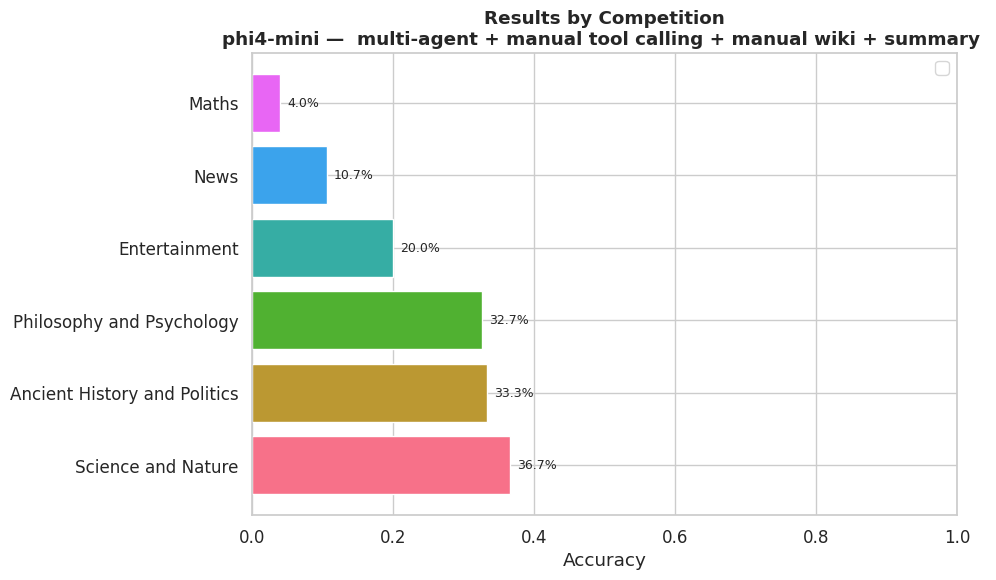

Plot displayed.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="husl", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})

def plot_accuracy_by_competition(runs_dir: Path):
    log_path = runs_dir / "runs_log.json"
    if not log_path.exists():
        print("No runs_log.json found at", log_path)
        return

    with open(log_path) as f:
        entries = json.load(f)

    if not entries:
        print("runs_log.json is empty.")
        return

    latest = entries[-1]
    comp_acc = latest.get("competition_accuracy", {})
    if not comp_acc:
        print("No competition_accuracy in latest run.")
        return

    comps = sorted(comp_acc.items(), key=lambda x: x[1], reverse=True)
    names, accs = zip(*comps)

    fig, ax = plt.subplots(figsize=(10, 6))
    pal = sns.color_palette("husl", len(names))
    bars = ax.barh(names, accs, color=pal, edgecolor='white')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Accuracy')
    ax.set_title(f'Results by Competition\n{latest.get("model_name", "")} —  multi-agent + manual tool calling + manual wiki + summary ', fontweight='bold')
    for bar, v in zip(bars, accs):
        ax.text(bar.get_width() + .01, bar.get_y() + bar.get_height() / 2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend()
    fig.tight_layout()
    plt.show()
    print("Plot displayed.")

plot_accuracy_by_competition(RUNS_DIR)

## Conclusions
The agent doesn't seem able to effectively extract summaries and to effectively run many tools.

The main issue was the time required to make the summary, which forced us to ask the models to make even shorter summaries degrading the performance. With a longer run of 10 games it was still able to archieve acceptable performance in many areas.